In [1]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import product
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay,
)
from itertools import combinations
from scipy import sparse
from threadpoolctl import threadpool_limits

SEED = 30
SAMPLE_FRACTION = 0.0005  # 0.05%
DATA_PATH = "datasets/USDOT_1987_2025_Flights_Dataset/flights_2008_2025_cleaned.parquet"

Our data from 2008-2025 is about 1.5M entries. To enable effective modelling we sampled only 0.05% of it. Using a SEED to ensure reproducibility.

In [2]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group)
        parts.append(table.take(rows).to_pandas())
    offset = end
data = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(data):,} flights")

Sample: 57,181 flights


To better understand the features are grouped into different categories:
- Calendar                                
- Scheduled flight information            
- Realized departure operations           
- Realized flight/arrival operations      
- Primary outcomes / possible targets     
- Disruption details and delay attribution

The table bellow groups these features into those categories:

The groups below distinguish variables known before departure from fields created during or after the flight. This matters because using a field that is unavailable at prediction time causes **target leakage**.

| Category                                 | Columns                                                                                                                                                                                               |
|------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Calendar                                 | `year`, `month`, `day`, `formatted_date`, `dayofweek`                                                                                                                                                 |
| Scheduled flight information             | `airline`, `iata_code_reporting_airline`, `flight_number`, `tail_number`, `origin_airport_id`, `dest_airport_id`, `crs_dep_time_hhmm`, `scheduled_arrival_hhmm`, `scheduled_elapsed_time`, `distance` |
| Realized departure operations            | `departure_time_hhmm`, `departure_delay`, `departure_delay_mins`, `taxi_out`, `wheels_off_hhmm`                                                                                                       |
| Realized flight/arrival operations       | `elapsed_time`, `air_time`, `wheels_on_hhmm`, `taxi_in`, `arrival_time_hhmm`                                                                                                                          |
| Primary outcomes / possible targets      | `arrival_delay`, `arrival_delay_mins`, `cancelled`, `diverted, departure_delay`                                                                                                                                        |
| Disruption details and delay attribution | `cancellation_code`, `airline_delay`, `weather_delay`, `air_system_delay`, `security_delay`, `late_aircraft_delay`, `div_reached_dest`, `div_actual_elapsed_time`                                     |

The target that will be used will be Departure Delay. Initialy Arrival Delay was used but our results showed that our features dont have enough information to explain the variance in Arrival Delay hence, we attempt this with Departure Delay

Selecting features

For our model we have to select features that are knnown before the flight occurs these are:

- Month
- Year
- DayofWeek
- Airline
- Distance
- Origin Airport
- Destination Airport 
- Scheduled Departure Time 
- Scheduled Elapsed Time
- Scheduled Arival Time 

First we will remove flights that were diverted or cancelled. Since these flights were not completed, it will not be usefull information in helping us predict arrival_delay.


In [3]:
sample = data.loc[(data["cancelled"] == 0) & (data["diverted"] == 0)].copy()
cols = sample.select_dtypes(include=["Int8", "Int16", "Int32", "Int64"]).columns
sample[cols] = sample[cols].astype("float64")
numeric = ["distance", "scheduled_elapsed_time"]
print(f"Eligible: {len(sample):,}; excluded: {len(data) - len(sample):,}")
sample[numeric].describe().round(2)

Eligible: 56,010; excluded: 1,171


,distance,scheduled_elapsed_time
count,56010.00,56010.00
mean,797.66,139.49
std,590.46,72.57
min,31.00,20.00
25%,368.00,86.00
50%,633.00,121.00
75%,1028.00,170.00
max,5095.00,705.00


Since `crs_dep_time_hhmm` and `scheduled_arrival_hhmm` are stored in HH:MM format, we need to convert these columns into numerical representations to facilitate data visualization and statistical analysis.

We will convert each time into the **number of minutes elapsed since midnight**. For example, 00:00 will correspond to 0 minutes, 06:00 to 360 minutes, and 12:00 to 720 minutes.

Special consideration must be given to flights that cross midnight, particularly those arriving on the following calendar day. Since this conversion only represents the time of day, it does not account for changes in calendar date or differences between airport time zones. These factors will need to be considered separately when calculating elapsed time or comparing departure and arrival times.

In [4]:
def hhmm_to_minutes(series):
    # Convert values to strings and remove colons
    times = (
        series.astype("string")
        .str.strip()
        .str.replace(":", "", regex=False)
    )

    # Convert HHMM strings into numbers
    times = pd.to_numeric(times, errors="coerce")

    # Extract hours and minutes
    hours = times // 100
    minutes = times % 100

    # Check for valid time values
    valid = (
        hours.between(0, 23)
        & minutes.between(0, 59)
    )

    # Convert to minutes since midnight
    total_minutes = hours * 60 + minutes

    return total_minutes.where(valid)

In [5]:
sample['scheduled_arrival_minutes'] = hhmm_to_minutes(sample['scheduled_arrival_hhmm'])
sample['crs_dep_time_minutes'] = hhmm_to_minutes(sample['crs_dep_time_hhmm'])
sample.drop('crs_dep_time_hhmm', axis=1, inplace=True)
sample.drop('scheduled_arrival_hhmm', axis=1, inplace=True)

In [6]:
sample[['scheduled_arrival_minutes', 'crs_dep_time_minutes', 'scheduled_elapsed_time']].describe()

,scheduled_arrival_minutes,crs_dep_time_minutes,scheduled_elapsed_time
count,56010.0,56010.0,56010.000000
mean,905.849813,803.908945,139.488716
std,300.196414,287.937479,72.566350
min,1.0,5.0,20.000000
25%,670.0,555.0,86.000000
50%,915.0,795.0,121.000000
75%,1152.0,1042.75,170.000000
max,1439.0,1439.0,705.000000


Since we have a separate DataFrame containing the airport IDs and their corresponding airport codes, we will map the numerical airport IDs to their respective airport codes. This will make the data easier to interpret and allow us to treat airports as categorical features in our regression analysis, rather than continuous numerical variables.

In [7]:
airport_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airports.csv')
airport_df = airport_df[['airport_id', 'airport_code']]

airport_dict = (
    airport_df
    .set_index("airport_id")["airport_code"]
    .to_dict()
)
sample['origin_airport'] = sample['origin_airport_id'].map(airport_dict)
sample['dest_airport'] = sample['dest_airport_id'].map(airport_dict)
sample.drop('dest_airport_id', axis=1, inplace=True)
sample.drop('origin_airport_id', axis=1, inplace=True)



In [8]:
airline_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airlines.csv')
airline_df = airline_df[['IATA_CODE_Reporting_Airline', 'airline_name']]

airline_dict = (
    airline_df
    .set_index("IATA_CODE_Reporting_Airline")["airline_name"]
    .to_dict()
)

sample['airline_name'] = sample['airline'].map(airline_dict)
sample['airline_name'] = sample['airline_name'].str.title()

We now drop the remaining columns not being used

In [9]:
features = [
    'month', 
    'year', 
    'dayofweek', 
    'formatted_date',
    'airline', 
    'origin_airport', 
    'distance', 
    'dest_airport', 
    'crs_dep_time_minutes', 
    'scheduled_elapsed_time', 
    'scheduled_arrival_minutes']


target = "departure_delay"

model_data = sample[features + [target]].copy()


In [10]:
len(model_data)

56010

In [11]:
model_data.describe()

,month,year,dayofweek,formatted_date,distance,crs_dep_time_minutes,scheduled_elapsed_time,scheduled_arrival_minutes,departure_delay
count,56010.000000,56010.000000,56010.000000,56010,56010.000000,56010.0,56010.000000,56010.0,56010.000000
mean,6.526638,2016.591912,3.954651,2017-02-02 19:46:54.825000,797.662757,803.908945,139.488716,905.849813,9.997250
min,1.000000,2008.000000,1.000000,2008-01-01 00:00:00,31.000000,5.0,20.000000,1.0,-31.000000
25%,4.000000,2012.000000,2.000000,2012-06-19 00:00:00,368.000000,555.0,86.000000,670.0,-5.000000
50%,7.000000,2017.000000,4.000000,2017-03-25 00:00:00,633.000000,795.0,121.000000,915.0,-2.000000
75%,9.000000,2021.000000,6.000000,2021-11-01 00:00:00,1028.000000,1042.75,170.000000,1152.0,7.000000
max,12.000000,2025.000000,7.000000,2025-12-31 00:00:00,5095.000000,1439.0,705.000000,1439.0,1468.000000
std,3.414977,5.296722,1.996465,NaN,590.458532,287.937479,72.566350,300.196414,44.484061


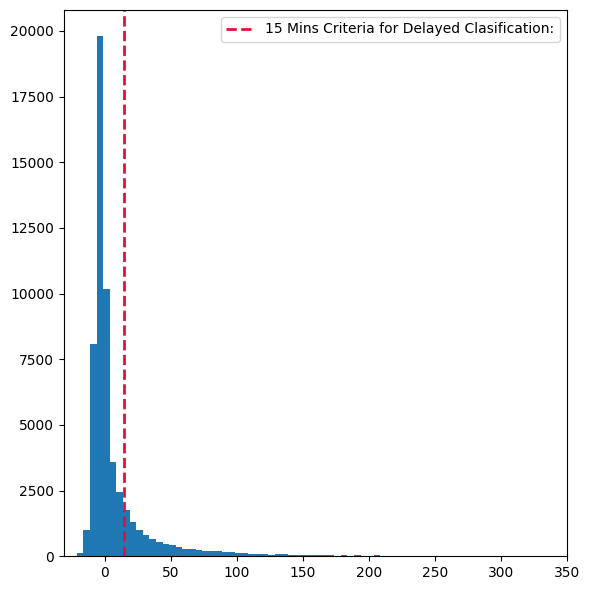

In [12]:

fig, ax = plt.subplots(figsize=(6, 6))
ax.hist(model_data[target], bins=300)
plt.xlim(min(model_data[target]),350)
ax.axvline(
    15,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"15 Mins Criteria for Delayed Clasification:")

plt.tight_layout()
plt.legend()
plt.show()


Looking at the histogram we can see that a majority of flights depart on time or early with about 50% of the sample departing 2 mins early. However we see a leading tail showing that there exist outliers and extreme cases.  To migate theier potential effects we will use the Interquatile Range Method to analyze them

In [13]:
q1 = model_data[target].quantile(0.25)
q3 = model_data[target].quantile(0.75)
IQR = q3-q1
print(f'Interquatile Range {IQR}')

outliers = [q1 -1.5*IQR, q3+1.5*IQR]

print(f'The range of our outliers {outliers}')


Interquatile Range 12.0
The range of our outliers [np.float64(-23.0), np.float64(25.0)]


In [14]:
n_outliers = len(model_data)- sum(model_data[target].between(-23,25))
print(f'Percent of outliers {(n_outliers/len(model_data))*100}')

Percent of outliers 12.96375647205856


Using IQR we see our outliers exist at [-23, 25]. It is feasible for flights to depart later than 25 minutes so even though they are outliers they are real possible entries. These extreme cases may however occur due to factors beyond the information our current features provide, i.e Mechanical Problems, Weather. 12% of our sample data are outliers. Like we saw when we developed a model with Arrival Time, our features may not provide enough information to explain the variance in the data.

So for this model we will retain the values within the outlier range

In [15]:
model_data = model_data.loc[model_data[target].between(-23,25)]

In [16]:
model_data['delay_stats'] = np.select(
    [
        model_data['departure_delay'] < 0,
        model_data['departure_delay'].between(0, 15),
        model_data['departure_delay'] > 15
    ],
    ['Early', 'On Time', 'Delayed'],
    default='Missing'
)



In [17]:
class_balance = pd.DataFrame({
    'Count': model_data['delay_stats'].value_counts(),
    'Percentage': model_data['delay_stats'].value_counts(normalize=True) * 100
})

class_balance.round(2)

,Count,Percentage
delay_stats,,
Early,32379,66.42
On Time,13634,27.97
Delayed,2736,5.61


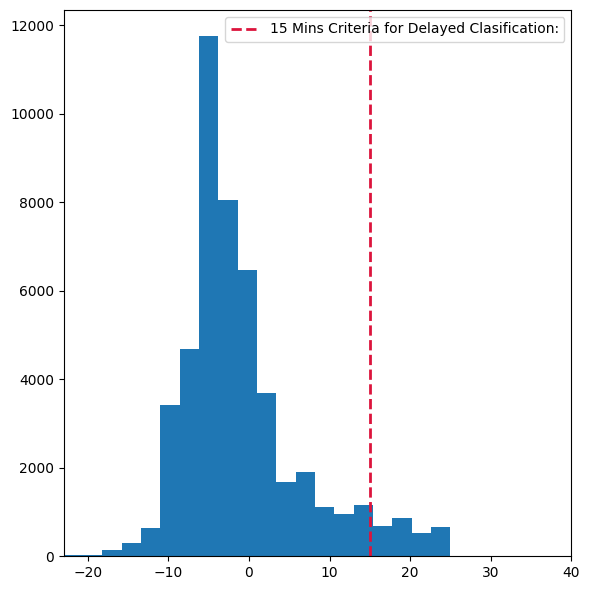

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.hist(model_data[target], bins=20)
plt.xlim(min(model_data[target]),40)
ax.axvline(
    15,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"15 Mins Criteria for Delayed Clasification:")

plt.tight_layout()
plt.legend()
plt.show()

## Multicollinearity

Now we review our features to asses multicolinearity

In [19]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]

correlation_matrix = model_data[numerical_features].corr()

display(correlation_matrix)

,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance
crs_dep_time_minutes,1.000000,0.736116,-0.017131,-0.009981
scheduled_arrival_minutes,0.736116,1.000000,0.041297,0.040318
scheduled_elapsed_time,-0.017131,0.041297,1.000000,0.983312
distance,-0.009981,0.040318,0.983312,1.000000


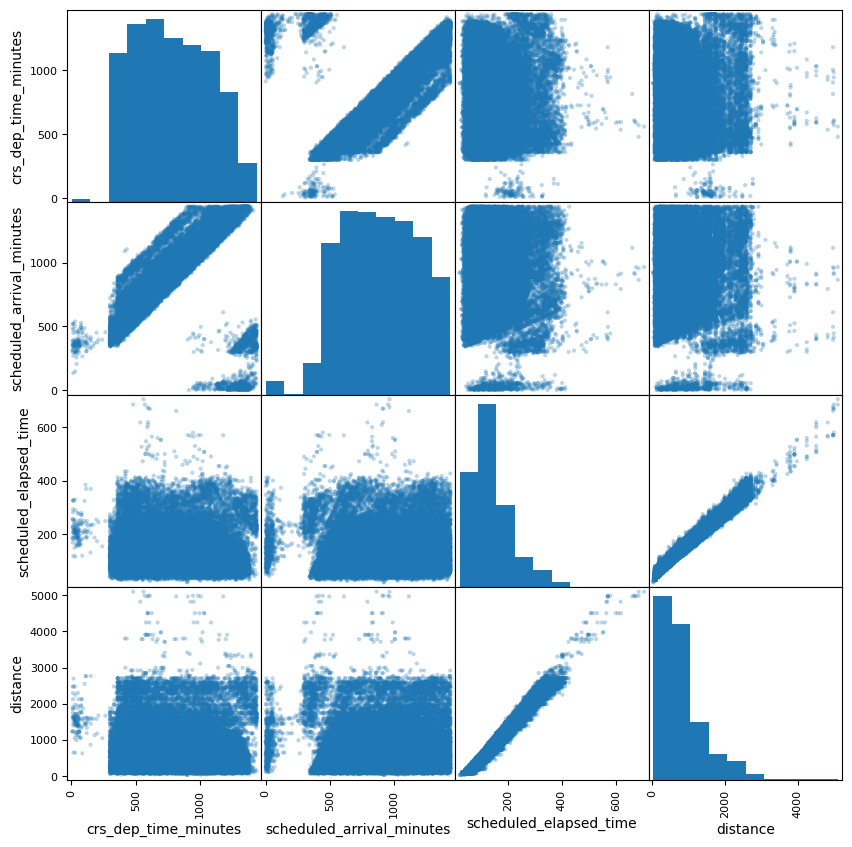

In [20]:
from pandas.plotting import scatter_matrix

scatter_matrix(
    model_data[numerical_features],
    figsize=(10, 10),
    alpha=0.3,
    diagonal="hist"
)

plt.show()

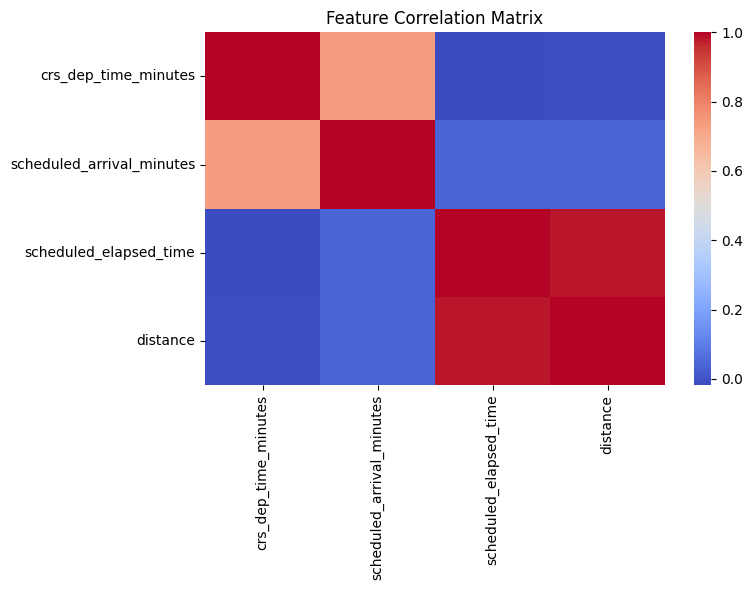

In [21]:
correlation_matrix = model_data[numerical_features].corr()

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix, cmap = "coolwarm")

ax.set_title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [22]:
X = model_data[numerical_features]
X = X.astype("float64")

# Include an intercept
X = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]

# Exclude intercept and sort by VIF
vif_data = (
    vif_data[vif_data["Feature"] != "const"]
    .sort_values("VIF", ascending=False)
)

display(vif_data)

,Feature,VIF
3,scheduled_elapsed_time,30.361897
4,distance,30.313745
1,crs_dep_time_minutes,2.200915
2,scheduled_arrival_minutes,2.200895


In [23]:
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport', ]

model_data[categorical_features].nunique()

month              12
year               18
dayofweek           7
airline            25
origin_airport    368
dest_airport      366
dtype: int64

### Categorizing Airports by Traffic 

We had earlier reduced the size of this categotrical variable by limiting to the Top 20 Airports. And even though that was beneficial in reducing complexity we may loose some information gained from less busier airports, for example what if smaller airports tend to have less delays? So it is possible that using specific airports may not be the effective way to go about it and we should categorizing airports based on their traffic. The FAA already does this using Yearly Enalpments data. They categorize airports based on the amount of passengers that board an aircraft rather than the total flights taken in an airport. The FAA categorizes airports into 5 hubs:
- L = Large
- M = Medium 
- S = Small
- N = Nonhub Primary
- None = All airports but Primary (NP)

In [24]:
data_2025 = pd.read_excel(r'datasets/USDOT_1987_2025_Flights_Dataset/enplanment/cy25-commercial-service-enplanements.xlsx')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


In [25]:
data_2025

,Rank,RO,ST,Locid,City,Airport Name,S/L,Hub,CY 25 Enplanements,CY 24 Enplanements,% Change
0,1.0,SO,GA,ATL,Atlanta,Hartsfield/Jackson Atlanta International,P,L,51459786.0,52511402.0,-0.0200
1,2.0,SW,TX,DFW,Fort Worth,Dallas-Fort Worth International,P,L,41297009.0,42351316.0,-0.0249
2,3.0,GL,IL,ORD,Chicago,Chicago O'Hare International,P,L,40680735.0,38575693.0,0.0546
3,4.0,NM,CO,DEN,Denver,Denver International,P,L,39976695.0,40012895.0,-0.0009
4,5.0,WP,CA,LAX,Los Angeles,Los Angeles International,P,L,36497303.0,37760834.0,-0.0335
...,...,...,...,...,...,...,...,...,...,...,...
517,562.0,AL,AK,CDB,Cold Bay,Cold Bay,CS,NaN,2567.0,3543.0,-0.2755
518,563.0,AL,AK,ADK,Adak (Naval) Station/Mitchell Field,Adak,CS,NaN,2524.0,2179.0,0.1583
519,564.0,AL,AK,IAN,Kiana,Bob Baker Memorial,CS,NaN,2509.0,2555.0,-0.0180
520,NaN,NaN,NaN,114,Nonprimary Commercial Service,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
storage = []
for year in range(8,26):
     if 8 <= year <= 10:
          enap = pd.read_excel(fr'datasets/USDOT_1987_2025_Flights_Dataset/enplanment/cy{year:02d}-commercial-service-enplanements.xls')
          enap['year'] = f'20{year:02d}'
     else:
          enap = pd.read_excel(fr'datasets/USDOT_1987_2025_Flights_Dataset/enplanment/cy{year}-commercial-service-enplanements.xlsx')
          enap['year'] = f'20{year:02d}'
     storage.extend(enap[['year','Locid','Hub']].values.tolist())


enap_df = pd.DataFrame(storage, columns=['year', 'Locid', 'Hub'])
     
        

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored"

In [27]:
enap_df = enap_df.dropna(how='all')

enap_df = enap_df[~enap_df[['Locid', 'Hub']].isna().all(axis=1)]
enap_df = enap_df[~enap_df.duplicated()]
enap_df = enap_df[~enap_df['Locid'].isna()]
enap_df = enap_df[~enap_df['Locid'].astype(str).str.fullmatch(r'\d+')]
enap_df.loc[enap_df['Hub'].isin(['-', '--', ]), 'Hub'] = "NP"
enap_df.loc[enap_df['Hub'].isna(), 'Hub'] = "NP"
enap_df['year'] = enap_df['year'].astype(float)


faa_data = enap_df.rename(columns={
    'Locid': 'airport_code',
    'Hub': 'airport_hub'
})

In [28]:
faa_data.to_csv('faa_enalpments.csv')

In [29]:
duplicates = faa_data.loc[
    faa_data.duplicated(
        subset=['airport_code', 'year'],
        keep=False
    )
].sort_values(['airport_code', 'year'])

duplicates

,year,airport_code,airport_hub


In [30]:
# Map old airport codes to new airport codes
airport_code_mapping = {
    'YUM': 'NYL',
    'FCA': 'GPI',
    'CLD': 'CRQ',
    'SCE': 'UNV',
    'AZA': 'IWA',
    'USA': 'JQF',
    'HHH': 'HXD',
    'PBI': 'DJT'
}

# Build lookup indexed by airport and year
hub_lookup = faa_data.set_index(
    ['airport_code', 'year']
)['airport_hub']

# Lookup using original airport code and year
original_keys = pd.MultiIndex.from_frame(
    model_data[['origin_airport', 'year']]
)

model_data['origin_airport_hub'] = hub_lookup.reindex(
    original_keys
).to_numpy()

# Lookup replacement codes only where the original hub is missing
missing = model_data['origin_airport_hub'].isna()

replacement_keys = pd.MultiIndex.from_arrays([
    model_data.loc[missing, 'origin_airport'].replace(airport_code_mapping),
    model_data.loc[missing, 'year']
])

model_data.loc[missing, 'origin_airport_hub'] = (
    hub_lookup.reindex(replacement_keys).to_numpy()
)

In [31]:
# Map old airport codes to new airport codes
airport_code_mapping = {
    'YUM': 'NYL',
    'FCA': 'GPI',
    'CLD': 'CRQ',
    'SCE': 'UNV',
    'AZA': 'IWA',
    'USA': 'JQF',
    'HHH': 'HXD',
    'PBI': 'DJT'
}

# Build lookup indexed by airport and year
hub_lookup = faa_data.set_index(
    ['airport_code', 'year']
)['airport_hub']

# Lookup using original airport code and year
original_keys = pd.MultiIndex.from_frame(
    model_data[['dest_airport', 'year']]
)

model_data['dest_airport_hub'] = hub_lookup.reindex(
    original_keys
).to_numpy()

# Lookup replacement codes only where the original hub is missing
missing = model_data['dest_airport_hub'].isna()

replacement_keys = pd.MultiIndex.from_arrays([
    model_data.loc[missing, 'dest_airport'].replace(airport_code_mapping),
    model_data.loc[missing, 'year']
])

model_data.loc[missing, 'dest_airport_hub'] = (
    hub_lookup.reindex(replacement_keys).to_numpy()
)

In [32]:
model_data.loc[model_data['dest_airport'] =='PBI']

,month,year,dayofweek,formatted_date,airline,origin_airport,distance,dest_airport,crs_dep_time_minutes,scheduled_elapsed_time,scheduled_arrival_minutes,departure_delay,delay_stats,origin_airport_hub,dest_airport_hub
682,3.0,2008.0,7.0,2008-03-16,FL,HPN,1057.0,PBI,838,165.0,1003,-6.0,Early,S,M
2587,12.0,2008.0,3.0,2008-12-03,US,CLT,590.0,PBI,980,107.0,1087,3.0,On Time,L,M
2826,9.0,2008.0,6.0,2008-09-20,AA,DFW,1103.0,PBI,805,165.0,1030,-5.0,Early,L,M
2965,10.0,2008.0,4.0,2008-10-30,FL,ATL,545.0,PBI,605,102.0,707,-3.0,Early,L,M
3048,10.0,2008.0,5.0,2008-10-17,US,DCA,857.0,PBI,899,147.0,1046,5.0,On Time,L,M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54038,6.0,2025.0,1.0,2025-06-16,AA,DFW,1102.0,PBI,640,175.0,875,-4.0,Early,L,M
54496,12.0,2025.0,2.0,2025-12-16,AA,DFW,1102.0,PBI,1120,157.0,1337,19.0,Delayed,L,M
55053,3.0,2025.0,3.0,2025-03-26,WN,BWI,883.0,PBI,520,170.0,690,13.0,On Time,L,M
55936,4.0,2025.0,7.0,2025-04-20,UA,EWR,1023.0,PBI,365,175.0,540,-3.0,Early,L,M


In [33]:
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport_hub', 
    'dest_airport_hub', ]

model_data[categorical_features].nunique()

month                 12
year                  18
dayofweek              7
airline               25
origin_airport_hub     5
dest_airport_hub       5
dtype: int64

In [34]:
final_features =[
    'distance', 
    'crs_dep_time_minutes', 
    'scheduled_elapsed_time', 
    'scheduled_arrival_minutes',    
    'C(month)', 
    'C(year)', 
    'C(dayofweek)', 
    'C(airline)', 
    'C(origin_airport_hub)', 
    'C(dest_airport_hub)']

In [35]:
sample['routes'] = sample['origin_airport'] + "-" + sample['dest_airport']

In [36]:
model_data['dest_airport_hub'] = (
    model_data['dest_airport_hub']
    .astype(object)
    .replace({pd.NA: np.nan})
)

Lets see what happen if when we do a multiple linear regression with the features we selected and no polynomial terms:


$\text{Departure Delay}(Y) = \beta_0 + \beta_1T_D +\sum_{j=1}^{p}\gamma_j C_j + \beta_2T_A + \beta_3T_E + \beta_4D$

In [37]:
regr_any = smf.ols(f"departure_delay ~ {(" + ".join(final_features))}", data=model_data, missing='drop').fit()

print(regr_any.summary())

                            OLS Regression Results                            
Dep. Variable:        departure_delay   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     69.13
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:59:45   Log-Likelihood:            -1.6579e+05
No. Observations:               48711   AIC:                         3.317e+05
Df Residuals:                   48640   BIC:                         3.323e+05
Df Model:                          70                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

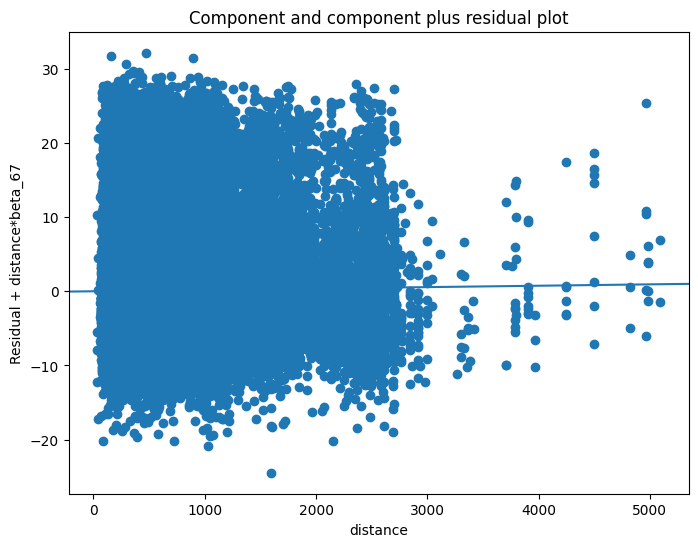

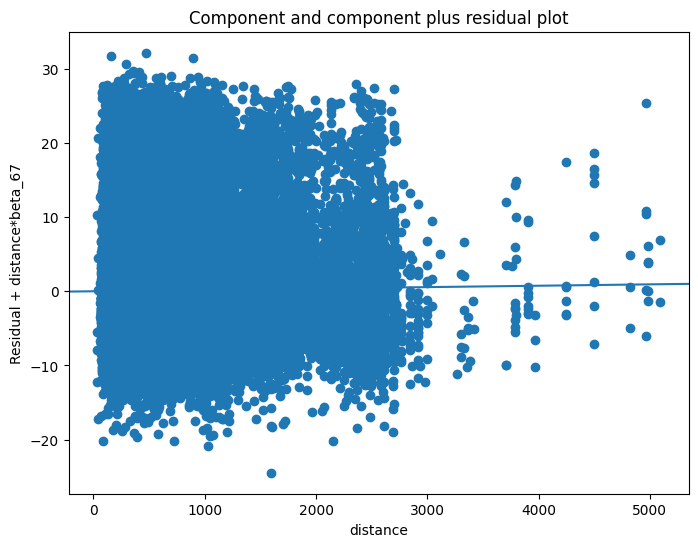

In [38]:
fig, ax = plt.subplots(figsize=(8,6))
sm.graphics.plot_ccpr(regr_any, 'distance', ax)

Lets see what happen if when we do a multiple linear regression with the features we selected and no polynomial terms:


$\text{Departure Delay}(Y) = \beta_0 + \beta_1T_D +\sum_{j=1}^{p}\gamma_j C_j + \beta_2T_A + \beta_3T_E + \beta_4D$

Where:

$T_D$: Scheduled Departure Time


$T_A$: Scheduled Arrival Time


$T_E$: Scheduled Ellapsed TIme


$D$: Distance


$p$: Total number of categorical dummy variables.



$j$: Index identifying each dummy variable, from 1 to \(p\).



$\gamma_j$: Regression coefficient associated with dummy variable \(j\).



$C_j$: Dummy variable indicating whether an observation belongs to a particular category (0 or 1).

In [39]:
columns = ['departure_delay', 'month', 'origin_airport_hub', 'dest_airport_hub']

model_data = model_data.dropna(subset=columns).copy()

In [40]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport_hub', 
    'dest_airport_hub', ]

TARGET = target
independent_variables = numerical_features + categorical_features

X = model_data[independent_variables].copy()
y = model_data[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
)

In [41]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical_onehot", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
        ("numerical", 'passthrough', numerical_features),
    ],
    remainder="drop",
)

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regression", LinearRegression()),
    ]
)
linear_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical_onehot', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

In [42]:
model = linear_model.named_steps['regression']

intercept = model.intercept_


In [43]:
y_pred = linear_model.predict(X_test)

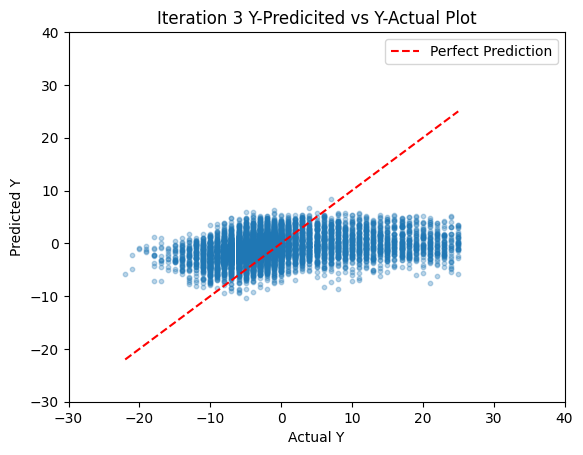

In [64]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(y_test, y_pred, alpha=0.3, s=10)

# Perfect prediction reference line
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], 'r--', label='Perfect Prediction')
plt.title('Iteration 3 Y-Predicited vs Y-Actual Plot')
plt.xlabel("Actual Y")
plt.ylabel("Predicted Y")
plt.xlim(-30, 40)
plt.ylim(-30, 40)
plt.legend()
plt.show()

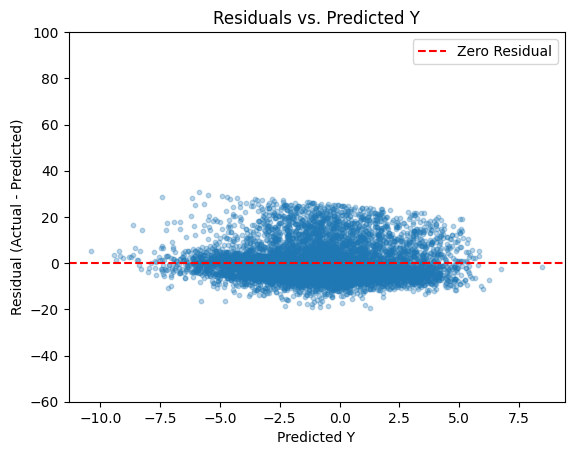

In [ ]:
residuals = y_test - y_pred

plt.scatter(y_pred, residuals, alpha=0.3, s=10)
plt.axhline(y=0, color='r', linestyle='--', label='Zero Residual')
plt.xlabel("Predicted Y")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Iteration 3 Residuals vs. Predicted Y")
plt.ylim(-60,100)
plt.legend()
plt.show()

In [45]:
#Mean baseline
y_baseline = np.full(len(y_test), y_train.mean())

# Compare models
results = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "RMSE": [
        root_mean_squared_error(y_test, y_baseline),
        root_mean_squared_error(y_test, y_pred)
    ],
    "MAE": [
        mean_absolute_error(y_test, y_baseline),
        mean_absolute_error(y_test, y_pred)
    ],
    "R²": [
        r2_score(y_test, y_baseline),
        r2_score(y_test, y_pred)
    ]
})

display(results.round(4))

,Model,RMSE,MAE,R²
0,Mean Baseline,7.5465,5.5226,-0.0002
1,Linear Regression,7.2257,5.2883,0.0831


From our results, we observe an RMSE of **7.34 minutes**, indicating that our model's predictions have a typical error magnitude of approximately 7 minutes. Our MAE is **5.37 minutes**, meaning that, on average, our predicted arrival delays differ from the actual delays by nearly 5.37 minutes.

Looking at the graph, we can see that our model struggles to accurately predict arrival delays beyond ±15 minutes, with predictions generally concentrated around a narrower range of values. Furthermore, our \(R^2\) value of **0.094** indicates that our model explains only **9.4% of the variance** in arrival delays within our test dataset.

The Linear Regression model outperformed the mean baseline in both RMSE and MAE. However, the improvements were marginal, suggesting that the model provides limited predictive value beyond the average arrival delay.

I believe class inbalance plays a part in why our model doesnt perform ver well. 5.6% of the flight in our sample are delayed so our model may end up being trained to predict on time arrivals. So in addition to providing more predictive features we will also need to find a way to prevent the inballance from affecting model performance. 

Next, we will analyze how introducing polynomial terms affects our model's performance. Unlike categorical features, numerical features can benefit from polynomial transformations because they allow our model to capture nonlinear relationships between the independent variables and arrival delays.

Categorical features, on the other hand, are one-hot encoded into binary values (0 or 1). Since squaring a binary value does not change its value, introducing higher-order polynomial terms for individual one-hot encoded features would have no additional effect on our model.

An example of a regression model incorporating a second-order polynomial term is:

$$
\text{Arrival Delay}(Y) = \beta_0 + \beta_1T_D + \sum_{j=1}^{p}\gamma_j C_j + \beta_2T_A + \beta_3T_E + \beta_4D + \beta_5D^2
$$

In this example, our **distance feature (D)** is assigned a polynomial degree of 2. By including both the linear and squared distance terms, we allow the model to capture a potential nonlinear relationship between flight distance and arrival delays.

In [46]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]

degrees = [1, 2, 3, 4]

degree_comb = list(product(degrees, repeat=len(numerical_features)))

print(degree_comb)
print(f"Total combinations: {len(degree_comb)}")

[(1, 1, 1, 1), (1, 1, 1, 2), (1, 1, 1, 3), (1, 1, 1, 4), (1, 1, 2, 1), (1, 1, 2, 2), (1, 1, 2, 3), (1, 1, 2, 4), (1, 1, 3, 1), (1, 1, 3, 2), (1, 1, 3, 3), (1, 1, 3, 4), (1, 1, 4, 1), (1, 1, 4, 2), (1, 1, 4, 3), (1, 1, 4, 4), (1, 2, 1, 1), (1, 2, 1, 2), (1, 2, 1, 3), (1, 2, 1, 4), (1, 2, 2, 1), (1, 2, 2, 2), (1, 2, 2, 3), (1, 2, 2, 4), (1, 2, 3, 1), (1, 2, 3, 2), (1, 2, 3, 3), (1, 2, 3, 4), (1, 2, 4, 1), (1, 2, 4, 2), (1, 2, 4, 3), (1, 2, 4, 4), (1, 3, 1, 1), (1, 3, 1, 2), (1, 3, 1, 3), (1, 3, 1, 4), (1, 3, 2, 1), (1, 3, 2, 2), (1, 3, 2, 3), (1, 3, 2, 4), (1, 3, 3, 1), (1, 3, 3, 2), (1, 3, 3, 3), (1, 3, 3, 4), (1, 3, 4, 1), (1, 3, 4, 2), (1, 3, 4, 3), (1, 3, 4, 4), (1, 4, 1, 1), (1, 4, 1, 2), (1, 4, 1, 3), (1, 4, 1, 4), (1, 4, 2, 1), (1, 4, 2, 2), (1, 4, 2, 3), (1, 4, 2, 4), (1, 4, 3, 1), (1, 4, 3, 2), (1, 4, 3, 3), (1, 4, 3, 4), (1, 4, 4, 1), (1, 4, 4, 2), (1, 4, 4, 3), (1, 4, 4, 4), (2, 1, 1, 1), (2, 1, 1, 2), (2, 1, 1, 3), (2, 1, 1, 4), (2, 1, 2, 1), (2, 1, 2, 2), (2, 1, 2, 3), (2, 1

In [47]:
hot_code = []
cat_formula = []
for cat in categorical_features:
    hot_code.append(f'C({cat})')
cat_formula.append(" + ".join(hot_code))
models = []
for combs in degree_comb:
    formula_terms = []

    for feature, degree in zip(numerical_features, combs):
        for power in range(1, degree + 1):
            if power == 1:
                formula_terms.append(feature)
            else:
                formula_terms.append(f"I({feature}**{power})")

    models.append(" + ".join(formula_terms + cat_formula))

In [48]:
results = []
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)


for df in [train_df, test_df]:
    cols = df.select_dtypes(include=["Int8", "Int16", "Int32", "Int64"]).columns
    df[cols] = df[cols].astype("float64")

fitted_models = []
    
for i, (formula, combs) in enumerate(zip(models, degree_comb)):

    model = smf.ols(
        formula=f"departure_delay ~ {formula}",
        data=train_df
    ).fit(missing='drop')
    fitted_models.append(model)
    predictions = model.predict(test_df)
    actual = test_df[target]

    results.append({
        "model_id": i,
        **dict(zip(numerical_features, combs)),
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions)
    })

results_df = pd.DataFrame(results)

In [49]:
display(results_df.sort_values('RMSE', ascending=True).head(5))
display(results_df.sort_values('MAE', ascending=True).head(5))
display(results_df.sort_values('R2', ascending=False).head(5))

,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
251,251,4,4,3,4,5.276737,7.200711,0.089389
215,215,4,2,2,4,5.278227,7.201638,0.089154
219,219,4,2,3,4,5.278292,7.201838,0.089104
235,235,4,3,3,4,5.278937,7.201980,0.089068
239,239,4,3,4,4,5.279220,7.202051,0.089050


,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
251,251,4,4,3,4,5.276737,7.200711,0.089389
211,211,4,2,1,4,5.277039,7.202531,0.088928
215,215,4,2,2,4,5.278227,7.201638,0.089154
219,219,4,2,3,4,5.278292,7.201838,0.089104
159,159,3,2,4,4,5.278296,7.203707,0.088631


,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
251,251,4,4,3,4,5.276737,7.200711,0.089389
215,215,4,2,2,4,5.278227,7.201638,0.089154
219,219,4,2,3,4,5.278292,7.201838,0.089104
235,235,4,3,3,4,5.278937,7.201980,0.089068
239,239,4,3,4,4,5.279220,7.202051,0.089050


In [50]:


def model_results(model, X_test, y_test):
    model = model
    X_eval = X_test.copy()

    y_pred = np.asarray(model.predict(X_eval)).ravel()
    y_actual = np.asarray(y_test).ravel()

    return y_pred, y_actual

# Reusable plotting function
def plot_predictions(ax, actual, predicted, title, limits=None):

    # Calculate performance metrics using all supplied observations
    mae = mean_absolute_error(actual, predicted)
    rmse = root_mean_squared_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    # Scatter plot
    ax.scatter(actual, predicted, alpha=0.3, s=10)

    # Determine axis limits
    if limits is None:
        low = min(actual.min(), predicted.min())
        high = max(actual.max(), predicted.max())

        low = np.floor(low / 50) * 50
        high = np.ceil(high / 50) * 50
    else:
        low, high = limits

    # Perfect prediction reference line
    ax.plot(
        [low, high],
        [low, high],
        "r--",
        label="Perfect Prediction"
    )

    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal", adjustable="box")

    # Title and metrics
    ax.set_title(
        f"{title}\n"
        f"MAE: {mae:.3f} | RMSE: {rmse:.3f} | R²: {r2:.4f}"
    )

    ax.set_xlabel("Actual Arrival Delay (min)")
    ax.set_ylabel("Predicted Arrival Delay (min)")
    ax.grid(alpha=0.2)
    ax.legend()




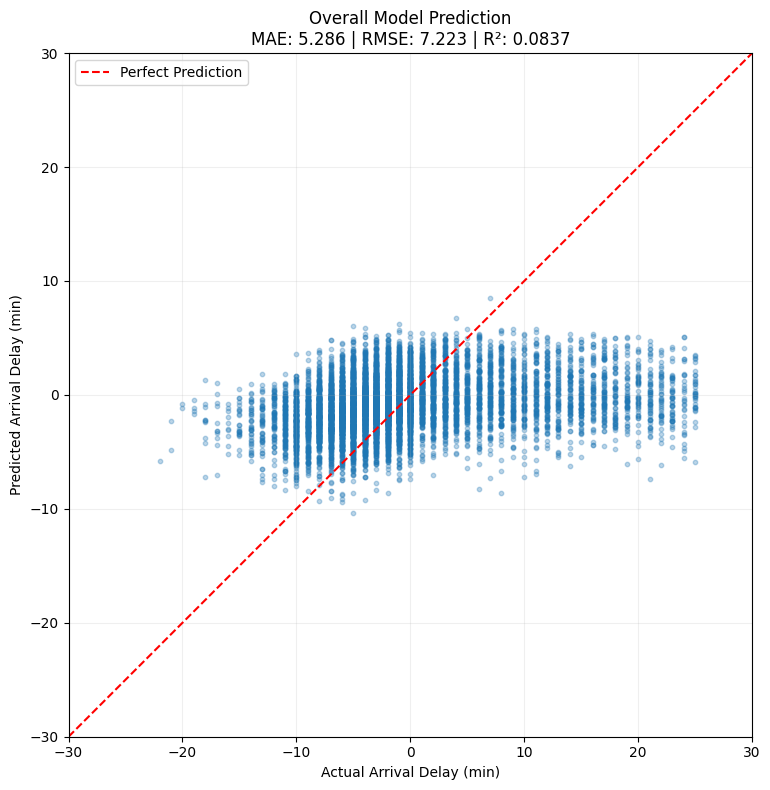

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Select fitted model
model = fitted_models[7]

y_pred, y_actual = model_results(model, X_test, y_test)

fig, axes = plt.subplots( figsize=(8, 8))

# 1. Overall model prediction
plot_predictions(
    axes,
    y_actual,
    y_pred,
    "Overall Model Prediction",
     limits=[-30,30]
)


plt.tight_layout()
plt.show()

### Polynomial Regression Analysis

To determine whether nonlinear relationships between our numerical features and arrival delays could improve our model's performance, we tested 81 combinations of polynomial degrees ranging from 1 to 3 across our four numerical features.

The table below highlights the three best-performing models based on RMSE.

| Model ID | Departure Time | Arrival Time | Elapsed Time | Distance | MAE | RMSE | R² |
|---|---|---|---|---|---|---|---|
| 71 | 3 | 2 | 3 | 3 | 21.860 | 37.584 | 0.02481 |
| 80 | 3 | 3 | 3 | 3 | 21.860 | 37.584 | 0.02480 |
| 63 | 3 | 2 | 1 | 1 | 21.852 | 37.588 | 0.02461 |

From our results, we observe that increasing polynomial complexity provides very little improvement in predictive performance. Our best-performing model achieves an RMSE of 37.58 minutes and an R² of 0.02481, explaining approximately **2.48% of the variance** in arrival delays. This is only a marginal improvement over our original linear regression, which achieved an R² of 0.0239.

Looking at our prediction graphs, we can see that the model continues to struggle with larger delays, with predictions concentrated within a relatively narrow range regardless of the actual arrival delay.

These findings suggest that introducing higher-order polynomial terms does not meaningfully improve our model's predictive ability. From a domain perspective, this makes sense because polynomial transformations only capture more complex relationships between existing features rather than introducing new information. Our results suggest that additional variables, such as weather conditions and operational disruptions, may be more useful in improving arrival delay predictions.

Next, we will investigate whether introducing **interaction terms involving airports** can improve our model's predictive performance. Unlike polynomial terms, which capture nonlinear relationships within individual features, interaction terms allow us to examine whether the relationship between one feature and arrival delays depends on another feature. For example, the effect of scheduled departure time may vary depending on the origin airport, as some airports experience greater congestion during certain hours. Similarly, specific origin and destination airport combinations may exhibit different historical delay patterns.

To evaluate these relationships, we will introduce airport interaction terms into our original linear regression model while retaining our existing features. We will test different interactions individually and compare their performance using MAE, RMSE, and R² against our baseline model. This will help us determine whether accounting for airport-specific operating patterns provides additional predictive information and improves our ability to estimate arrival delays.

In [52]:
airport_interactions = {
    "Origin × Departure Time":
        "C(origin_airport_hub):crs_dep_time_minutes",

    "Origin × Distance":
        "C(origin_airport_hub):distance",

    "Destination × Arrival Time":
        "C(dest_airport_hub):scheduled_arrival_minutes",

    "Origin × Destination":
        "C(origin_airport_hub):C(dest_airport_hub)"
}

numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = (
    TARGET + " ~ " +
    " + ".join(numerical_formula + categorical_formula)
)

In [53]:
results = []
fitted_models = {}

# Baseline + individual interactions
formulas = {"Baseline": baseline_formula}

for name, interaction in airport_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction

# Fit and evaluate each model
for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
1,Origin × Departure Time,5.285107,7.223449,0.083629,75
3,Destination × Arrival Time,5.287859,7.223906,0.083513,75
4,Origin × Destination,5.286494,7.224850,0.083273,87
2,Origin × Distance,5.287267,7.224970,0.083243,75
0,Baseline,5.287613,7.224988,0.083238,71


In [54]:
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
1,Origin × Departure Time,5.285107,7.223449,0.083629,75
3,Destination × Arrival Time,5.287859,7.223906,0.083513,75
4,Origin × Destination,5.286494,7.224850,0.083273,87
2,Origin × Distance,5.287267,7.224970,0.083243,75
0,Baseline,5.287613,7.224988,0.083238,71


In [55]:
airline_interactions = {
    "airline × Departure Time":
        "C(airline):crs_dep_time_minutes",

    "airline × Distance":
        "C(airline):distance",

    "airline × Arrival Time":
        "C(airline):scheduled_arrival_minutes",

    "airline × Destination":
        "C(airline):C(dest_airport_hub)"
}

numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = (
    TARGET + " ~ " +
    " + ".join(numerical_formula + categorical_formula)
)

In [56]:
results = []
fitted_models = {}

# Baseline + individual interactions
formulas = {"Baseline": baseline_formula}

for name, interaction in airline_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction

# Fit and evaluate each model
for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
3,airline × Arrival Time,5.268198,7.215237,0.085711,95
1,airline × Departure Time,5.268535,7.217355,0.085174,95
0,Baseline,5.287613,7.224988,0.083238,71
4,airline × Destination,5.295006,7.235804,0.080491,167
2,airline × Distance,5.292164,7.239181,0.079633,95


In [57]:
departure_interactions = {
    "Airline × Departure Time":
        "C(airline):crs_dep_time_minutes",

    "Origin × Departure Time":
        "C(origin_airport_hub):crs_dep_time_minutes",

    "Both Departure Interactions":
        "C(airline):crs_dep_time_minutes"
        " + C(origin_airport_hub):crs_dep_time_minutes"
}
numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = TARGET + " ~ " + " + ".join(
    numerical_formula + categorical_formula
)

formulas = {"Baseline": baseline_formula}

for name, interaction in departure_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction




In [58]:
results = []
fitted_models = {}

for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)

display(results_df.sort_values("RMSE"))

,Interaction,MAE,RMSE,R2,Parameters
1,Airline × Departure Time,5.268535,7.217355,0.085174,95
3,Both Departure Interactions,5.268230,7.218274,0.084941,99
2,Origin × Departure Time,5.285107,7.223449,0.083629,75
0,Baseline,5.287613,7.224988,0.083238,71


In [59]:
from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

import statsmodels.formula.api as smf
import pandas as pd
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

cv_results = []

for name, formula in formulas.items():

    fold_metrics = []

    for train_idx, val_idx in cv.split(train_df):

        # Split training data into folds
        fold_train = train_df.iloc[train_idx]
        fold_val = train_df.iloc[val_idx]

        # Fit model
        model = smf.ols(
            formula=formula,
            data=fold_train
        ).fit()

        # Predict
        predictions = model.predict(fold_val)
        actual = fold_val[TARGET]

        # Store fold metrics
        fold_metrics.append({
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": root_mean_squared_error(actual, predictions),
            "R2": r2_score(actual, predictions)
        })

    fold_df = pd.DataFrame(fold_metrics)

    # Store average performance and variation
    cv_results.append({
        "Interaction": name,
        "MAE_mean": fold_df["MAE"].mean(),
        "MAE_std": fold_df["MAE"].std(),
        "RMSE_mean": fold_df["RMSE"].mean(),
        "RMSE_std": fold_df["RMSE"].std(),
        "R2_mean": fold_df["R2"].mean(),
        "R2_std": fold_df["R2"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.sort_values("RMSE_mean"))

,Interaction,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
1,Airline × Departure Time,5.307781,0.039611,7.296753,0.078042,0.089865,0.005318
3,Both Departure Interactions,5.306437,0.040033,7.296913,0.078249,0.089825,0.005445
2,Origin × Departure Time,5.323285,0.040380,7.304004,0.079228,0.088058,0.005297
0,Baseline,5.325628,0.038934,7.304503,0.078351,0.087933,0.004988


We have a lot of categorical data so we will use different visual to display each categories relation to arrival_delay

### Cross-Validation of Interaction Models

To evaluate whether the improvements observed from our interaction terms were consistent, we performed 5-fold cross-validation across our baseline model and three departure-time interaction models.

| Model | Mean MAE | Mean RMSE | Mean R² | RMSE Std |
|---|---:|---:|---:|---:|
| Baseline | 22.607 | 42.479 | 0.02359 | 2.674 |
| Airline × Departure Time | **22.557** | **42.448** | **0.02503** | 2.682 |
| Origin × Departure Time | 22.615 | 42.472 | 0.02392 | 2.674 |
| Both Departure Interactions | 22.580 | 42.455 | 0.02467 | 2.676 |

Our results show that Airline × Departure Time produces the best average performance, achieving an R² of 0.0250 compared with the baseline's 0.0236. However, the improvement in RMSE is only approximately 0.03 minutes.

Additionally, combining both departure-time interactions does not improve performance beyond the airline interaction alone. These findings suggest that while departure-time effects may vary by airline, the additional predictive information is limited.

Overall, cross-validation supports our earlier findings that increasing model complexity through interaction terms provides only marginal improvements in predicting arrival delays.

In [60]:
# Save the finalized modelling dataset
model_data.to_parquet(
    "model_data_air_raffic.parquet",
    index=False
)

In [61]:
from sklearn.model_selection import train_test_split
import numpy as np
# Create a persistent split
train_idx, test_idx = train_test_split(
    np.arange(len(model_data)),
    test_size=0.2,
    random_state=SEED
)

# Save indices
np.savez(
    "model_split_air_traffic.npz",
    train_idx=train_idx,
    test_idx=test_idx
)